# 18 · Can weights learned from A1 beat the hand-set score on A2?

**Question.** The X2 score is `2·role_match + experience_compatible + 0.999·tfidf_scaled`. If we *learn* those weights from A1 labels (four features, one logistic regression), does the A2 final-set ordering improve?

**Arms** (Fit = Good ∪ Potential; each fit is a 4-weight logistic regression, `class_weight=balanced`):

| Arm | Training pairs | Labels |
|---|---|---|
| **A** original, all | 3,990 A1 train | A1's own |
| **B** original, matched | the 639 pairs the LLM labelled | A1's own (size control) |
| **C** LLM, matched | the same 639 pairs | claude-sonnet-5, run 2 |

Compared with the **hand-set X2** (weights 2, 1, 0.999, 0) on the same four features, TF-IDF alone and the rule alone.

**Status.** `exploratory`, run under a user-authorised exception to D43/D51 (12 Oct 2026): existing LLM label files are read, no model is called, nothing is adopted. A1's original labels do not reproduce (D33/A13); the LLM-labelled 639 pairs are 87% No Fit.

**Bar, written before the results** (rule 8): an arm beats hand-set X2 only if its paired total ΔAUC has a CI above 0 **and** `generic` and `targeted` both have a positive Δ. Otherwise: no evidence of improvement.

Code: `candidate_screener.evaluation.a1_weights`. Scorer: `evaluation.indomain`. Features come from A1 text alone; A2 labels are read only by the scorer (D46).

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from candidate_screener import reporting
from candidate_screener.evaluation import a1_weights as aw, final_set, indomain, stage1
from candidate_screener.matching import corpus, lexical

reporting.style(plt)
SEED = 0

# --- A2 final set: the exam ---
frame = final_set.load(); RULE_VERSION = int(frame.rule_version.iloc[0]); lab = indomain.labels(frame)
a2 = (corpus.a2_pairs(text_variant="v2").assign(keyword_match=lambda d: corpus.keyword_match(d))
      .set_index("pair_id").loc[lab.index].reset_index())

# --- A1: training pairs and the two label sets ---
a1_train = corpus.a1_pairs("train"); a1_test = corpus.a1_pairs("test")
llm = aw.llm_labels()
a1_all = pd.concat([a1_train, a1_test]).drop_duplicates("pair_id").set_index("pair_id", drop=False)
matched = a1_all.loc[llm.index]                          # the 639 LLM-labelled pairs (all in A1 test)
orig = a1_all.fit.astype(int)                            # A1's own Fit / No Fit
print(f"A1 train {len(a1_train):,} pairs; LLM-labelled {len(llm)} pairs over {matched.jd_id.nunique()} JDs")
print("Fit rate  A1 original (all train): %.2f | original (matched): %.2f | LLM (matched): %.2f"
      % (orig.loc[a1_train.pair_id].mean(), orig.loc[llm.index].mean(), llm.mean()))

A1 train 3,990 pairs; LLM-labelled 639 pairs over 100 JDs
Fit rate  A1 original (all train): 0.50 | original (matched): 0.47 | LLM (matched): 0.13


In [2]:
model = aw.build_scorer()
X_a2 = aw.features(model, a2)
X_train = aw.features(model, a1_train)
X_match = aw.features(model, matched)
print(X_a2.shape, X_train.shape, X_match.shape)

(600, 4) (3990, 4) (639, 4)


## Learned weights

In [3]:
arms = {
    "A · original, all (n=3,990)":       aw.fit_weights(X_train, orig.loc[X_train.index]),
    "B · original, matched (n=639)":     aw.fit_weights(X_match, orig.loc[X_match.index]),
    "C · LLM, matched (n=639)":          aw.fit_weights(X_match, llm.loc[X_match.index]),
}
W = {"hand-set X2": pd.Series(aw.HAND_WEIGHTS, index=aw.FEATURES), **arms}
weights = pd.DataFrame(W).T
weights["role : exp : text"] = [f"{w[0]/w[2]:.1f} : {w[1]/w[2]:.1f} : 1" if w[2] > 0 else "-" for w in weights[list(aw.FEATURES)].to_numpy()]
weights.round(2)

,role_match,experience_compatible,tfidf_scaled,coverage,role : exp : text
hand-set X2,2.00,1.00,1.00,0.00,2.0 : 1.0 : 1
"A · original, all (n=3,990)",0.98,-0.42,1.10,0.10,0.9 : -0.4 : 1
"B · original, matched (n=639)",0.66,-0.30,0.73,0.44,0.9 : -0.4 : 1
"C · LLM, matched (n=639)",3.60,0.26,2.34,1.55,1.5 : 0.1 : 1


## Result: A2 final set, per-JD AUC

`generic`, `targeted`, `total` with JD-bootstrap CIs (n = 39 / 20 / 59 JDs); `within-family` removes the same-role shortcut.

In [4]:
unscoreable = []
def figs_of(name, scores):
    f = [x.as_dict() for x in indomain.rank_figures(name, scores, lab, a2, RULE_VERSION, SEED, unscoreable)]
    indomain.assert_total_has_strata(f); return {(x["metric"], x["scope"], x["subset"]): x for x in f}

scores = {name: aw.linear_score(X_a2, w) for name, w in W.items()}
scores["TF-IDF alone"] = aw.linear_score(X_a2, np.array([0, 0, 1.0, 0]))
scores["rule alone (X1)"] = aw.linear_score(X_a2, np.array([2.0, 1.0, 0, 0]))
rows = []
for name, s in scores.items():
    f = figs_of(name, s)
    rows.append({"model": name, **{sc: f[("auc", sc, "all")]["value"] for sc in final_set.SCOPES},
                 "total CI": f"[{f[('auc','total','all')]['ci_low']:.3f}, {f[('auc','total','all')]['ci_high']:.3f}]",
                 "within-family": f[("within_family_auc", "total", "all")]["value"],
                 "llm_free total": f[("auc", "total", "llm_free")]["value"]})
results = pd.DataFrame(rows)
results.round(3)

,model,generic,targeted,total,total CI,within-family,llm_free total
0,hand-set X2,0.863,0.826,0.850,"[0.809, 0.889]",0.745,0.900
1,"A · original, all (n=3,990)",0.860,0.798,0.839,"[0.797, 0.878]",0.735,0.879
2,"B · original, matched (n=639)",0.861,0.816,0.846,"[0.805, 0.885]",0.754,0.884
3,"C · LLM, matched (n=639)",0.871,0.828,0.856,"[0.815, 0.894]",0.761,0.899
4,TF-IDF alone,0.780,0.807,0.789,"[0.741, 0.835]",0.714,0.826
5,rule alone (X1),0.851,0.755,0.818,"[0.765, 0.867]",0.678,0.866


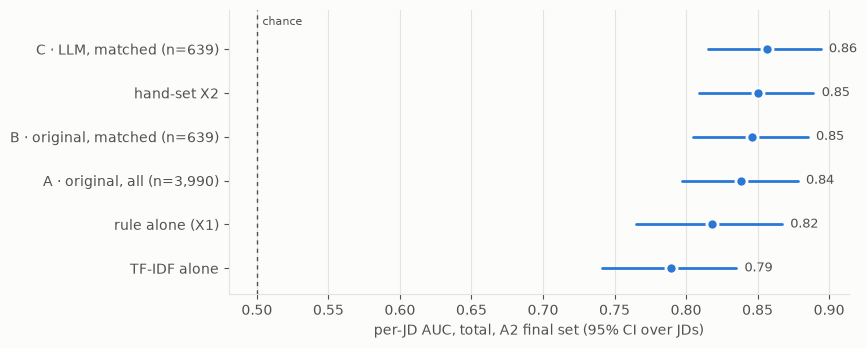

In [5]:
order = results.sort_values("total")
cis = [[float(v) for v in r.strip("[]").split(",")] for r in order["total CI"]]
fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 1))
reporting.dot_ci(ax, list(order.model)[::-1], list(order.total)[::-1], [c[0] for c in cis][::-1], [c[1] for c in cis][::-1], ref=0.5, ref_label="chance")
ax.set_xlabel("per-JD AUC, total, A2 final set (95% CI over JDs)"); plt.show()

## Paired deltas against the hand-set X2 (the bar)

In [6]:
def delta_table(pairs_to_compare):
    rows = []
    for b, a in pairs_to_compare:
        d = {sc: indomain.paired_delta(scores[b], scores[a], lab, a2, "auc", sc, "all", SEED) for sc in final_set.SCOPES}
        rows.append({"B": b, "A": a, **{f"Δ {sc}": d[sc]["delta"] for sc in final_set.SCOPES},
                     "total CI": d["total"]["ci"], "n_jd": d["total"]["n_jd"],
                     "bar met": bool(d["total"]["ci"][0] > 0 and d["generic"]["delta"] > 0 and d["targeted"]["delta"] > 0)})
    return pd.DataFrame(rows)

hand = "hand-set X2"
delta_table([(k, hand) for k in W if k != hand])

,B,A,Δ generic,Δ targeted,Δ total,total CI,n_jd,bar met
0,"A · original, all (n=3,990)",hand-set X2,-0.003291,-0.028357,-0.011788,"[-0.033799, 0.010241]",59,False
1,"B · original, matched (n=639)",hand-set X2,-0.001535,-0.009923,-0.004379,"[-0.02606, 0.017369]",59,False
2,"C · LLM, matched (n=639)",hand-set X2,0.007970,0.001637,0.005823,"[-0.008626, 0.021007]",59,False


### Does the label source matter? (same 639 pairs)

In [7]:
delta_table([("C · LLM, matched (n=639)", "B · original, matched (n=639)"),
             ("A · original, all (n=3,990)", "B · original, matched (n=639)"),
             ("A · original, all (n=3,990)", "C · LLM, matched (n=639)")])

,B,A,Δ generic,Δ targeted,Δ total,total CI,n_jd,bar met
0,"C · LLM, matched (n=639)","B · original, matched (n=639)",0.009505,0.011560,0.010202,"[-0.003753, 0.024528]",59,False
1,"A · original, all (n=3,990)","B · original, matched (n=639)",-0.001755,-0.018435,-0.007409,"[-0.013927, -0.001318]",59,False
2,"A · original, all (n=3,990)","C · LLM, matched (n=639)",-0.011261,-0.029994,-0.017611,"[-0.033322, -0.002635]",59,False


### Reading the result

See the tables above. `bar met` is the rule written before the run. Weights are on one scale because all four features lie in [0, 1], so the `role : exp : text` ratio shows whether a source asks for more or less role weight than the hand-set 2 : 1 : 1.

---
# Part 2 · Add extracted concepts, skills and experience

**Question.** Do richer text-only features let the learned weights beat hand-set X2 where four could not?

| Feature set | Added terms (all from text; no metadata) |
|---|---|
| base (4) | role_match, experience_compatible, tfidf_scaled, coverage (IDF-weighted) |
| + concepts / skills | unweighted coverage, log #matched concepts, log #JD concepts, log #CV concepts, vocabulary skill overlap (rung 1b, no context filter) |
| + experience | extracted years gap (CV years − JD minimum, clipped ±10, scaled) and a "both known" flag |
| all | both blocks |

Each feature set is fitted on each label source (A, B, C), so 12 fits and 9 comparisons with hand-set X2. **Same bar as Part 1**, written before running: paired total ΔAUC CI above 0 and positive on both strata. With 9 comparisons, one nominal pass would not be evidence on its own; I will say so if it happens.

In [8]:
X_a2e = X_a2.join(aw.extra_features(model, a2))
X_traine = X_train.join(aw.extra_features(model, a1_train))
X_matche = X_match.join(aw.extra_features(model, matched))
sources = {"A · original, all": (X_traine, orig), "B · original, matched": (X_matche, orig), "C · LLM, matched": (X_matche, llm)}
grid, learned = {}, {}
for fs_name, cols in aw.FEATURE_SETS.items():
    for src, (X, y) in sources.items():
        w = aw.fit_weights(X, y.loc[X.index], cols)
        learned[(fs_name, src)] = w
        scores[(fs_name, src)] = aw.linear_score(X_a2e, w)
        grid[(fs_name, src)] = figs_of(f"{fs_name} | {src}", scores[(fs_name, src)])[("auc", "total", "all")]["value"]
pd.Series(grid).unstack()[list(sources)].round(3).rename_axis("total AUC")

,"A · original, all","B · original, matched","C · LLM, matched"
total AUC,,,
+ concepts / skills,0.848,0.774,0.841
+ experience,0.835,0.815,0.854
all,0.839,0.761,0.847
base (4),0.839,0.846,0.856


### Paired deltas vs hand-set X2 (bar applies; 9 comparisons)

In [9]:
rows = []
for (fs_name, src), s in ((k, scores[k]) for k in learned if k[0] != "base (4)"):
    d = {sc: indomain.paired_delta(s, scores[hand], lab, a2, "auc", sc, "all", SEED) for sc in final_set.SCOPES}
    rows.append({"features": fs_name, "labels": src, **{f"Δ {sc}": d[sc]["delta"] for sc in final_set.SCOPES},
                 "total CI": d["total"]["ci"], "bar met": bool(d["total"]["ci"][0] > 0 and d["generic"]["delta"] > 0 and d["targeted"]["delta"] > 0)})
pd.DataFrame(rows).round(4)

,features,labels,Δ generic,Δ targeted,Δ total,total CI,bar met
0,+ concepts / skills,"A · original, all",0.0062,-0.0196,-0.0026,"[-0.025396, 0.019953]",False
1,+ concepts / skills,"B · original, matched",-0.0534,-0.1218,-0.0765,"[-0.123158, -0.032803]",False
2,+ concepts / skills,"C · LLM, matched",0.0028,-0.0328,-0.0092,"[-0.031118, 0.012604]",False
3,+ experience,"A · original, all",-0.0071,-0.0311,-0.0152,"[-0.042604, 0.011708]",False
4,+ experience,"B · original, matched",-0.0285,-0.0487,-0.0354,"[-0.065528, -0.007427]",False
5,+ experience,"C · LLM, matched",0.0089,-0.0070,0.0035,"[-0.014125, 0.02219]",False
6,all,"A · original, all",0.0014,-0.0351,-0.0109,"[-0.039061, 0.016013]",False
7,all,"B · original, matched",-0.0618,-0.1445,-0.0898,"[-0.135641, -0.046938]",False
8,all,"C · LLM, matched",0.0066,-0.0241,-0.0038,"[-0.029589, 0.021623]",False


### Does adding features help its own base? (paired, same label source)

In [10]:
rows = []
for src in sources:
    for fs_name in list(aw.FEATURE_SETS)[1:]:
        d = indomain.paired_delta(scores[(fs_name, src)], scores[("base (4)", src)], lab, a2, "auc", "total", "all", SEED)
        rows.append({"labels": src, "features": fs_name, "Δ total vs base": d["delta"], "CI": d["ci"]})
pd.DataFrame(rows).round(4)

,labels,features,Δ total vs base,CI
0,"A · original, all",+ concepts / skills,0.0092,"[-0.003044, 0.021842]"
1,"A · original, all",+ experience,-0.0035,"[-0.01886, 0.011283]"
2,"A · original, all",all,0.0008,"[-0.017521, 0.018245]"
3,"B · original, matched",+ concepts / skills,-0.0722,"[-0.117467, -0.031306]"
4,"B · original, matched",+ experience,-0.0310,"[-0.049194, -0.014415]"
5,"B · original, matched",all,-0.0854,"[-0.126187, -0.047563]"
6,"C · LLM, matched",+ concepts / skills,-0.0150,"[-0.029163, -0.00102]"
7,"C · LLM, matched",+ experience,-0.0023,"[-0.013065, 0.009752]"
8,"C · LLM, matched",all,-0.0096,"[-0.02798, 0.008222]"


### Learned weights, all features (C · LLM, matched, and A · original, all)

In [11]:
pd.DataFrame({"A · original, all": learned[("all", "A · original, all")], "C · LLM, matched": learned[("all", "C · LLM, matched")]}).round(2)

,"A · original, all","C · LLM, matched"
role_match,0.94,3.27
experience_compatible,-0.61,0.48
tfidf_scaled,1.04,2.16
coverage,-0.13,-0.16
coverage_unweighted,-0.07,-0.00
log_matched,0.32,1.88
log_jd_concepts,0.04,-1.44
log_cv_concepts,-0.05,-0.10
skill_overlap,-0.10,0.06
exp_gap,0.05,-0.13
